<a href="https://colab.research.google.com/github/GAJIN-S/ML/blob/main/transformer%20english%20-%20spanish.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!pip install -q datasets sentencepiece sacrebleu matplotlib pandas tqdm


In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F
import sentencepiece as spm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import math
import os
import random

from datasets import load_dataset
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Enable GPU in Colab runtime settings.")


PyTorch version: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


In [ ]:

# Dataset configuration
SOURCE_LANG = "en"
TARGET_LANG = "es"

# Dataset split
TRAIN_RATIO = 0.80
VALID_RATIO = 0.10
TEST_RATIO = 0.10

# Transformer configuration
D_MODEL = 256
NUM_HEADS = 8
NUM_ENCODER_LAYERS = 4
NUM_DECODER_LAYERS = 4
D_FF = 1024
DROPOUT = 0.1

# Training configuration
BATCH_SIZE = 64
LEARNING_RATE = 0.0003
EPOCHS = 20

MAX_LENGTH = 80

print("Configuration initialized successfully!")


Configuration initialized successfully!


In [ ]:
dataset = load_dataset(
    "Helsinki-NLP/opus_books",
    "en-es"
)

print(dataset)

README.md:   0%|          | 0.00/28.1k [00:00<?, ?B/s]

en-es/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 16.1MB            

en-es/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/93470 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'translation'],
        num_rows: 93470
    })
})


In [ ]:

train_data = dataset["train"]

print("Total sentence pairs:", len(train_data))

print("\nFirst 5 sentence pairs:\n")

for i in range(5):
    sample = train_data[i]["translation"]

    print("English:", sample["en"])
    print("Spanish:", sample["es"])
    print("-" * 60)


Total sentence pairs: 93470

First 5 sentence pairs:

English: Source: Project GutenbergAudiobook available here
Spanish: Source: Wikisource & librodot.com
------------------------------------------------------------
English: Sense and Sensibility
Spanish: SENTIDO Y SENSIBILIDAD
------------------------------------------------------------
English: Jane Austen
Spanish: JANE AUSTEN
------------------------------------------------------------
English: CHAPTER 1
Spanish: CAPITULO I
------------------------------------------------------------
English: The family of Dashwood had long been settled in Sussex.
Spanish: La familia Dashwood llevaba largo tiempo afincada en Sussex.
------------------------------------------------------------


In [ ]:

import re

def clean_text(text):
    text = str(text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text)

    return text.strip()


# Extract sentence pairs
english_sentences = []
spanish_sentences = []

seen = set()

for item in train_data:

    english = clean_text(item["translation"]["en"])
    spanish = clean_text(item["translation"]["es"])

    # Remove empty sentences
    if not english or not spanish:
        continue

    # Remove excessively long sentences
    if len(english.split()) > 80 or len(spanish.split()) > 80:
        continue

    # Remove duplicates
    pair = (english, spanish)

    if pair in seen:
        continue

    seen.add(pair)

    english_sentences.append(english)
    spanish_sentences.append(spanish)


print("Cleaned sentence pairs:", len(english_sentences))

df = pd.DataFrame({
    "english": english_sentences,
    "spanish": spanish_sentences
})

print(df.head(10))

print("\nDataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate pairs:", df.duplicated().sum())



Cleaned sentence pairs: 90142
                                             english  \
0  Source: Project GutenbergAudiobook available here   
1                              Sense and Sensibility   
2                                        Jane Austen   
3                                          CHAPTER 1   
4  The family of Dashwood had long been settled i...   
5  Their estate was large, and their residence wa...   
6  The late owner of this estate was a single man...   
7  But her death, which happened ten years before...   
8  In the society of his nephew and niece, and th...   
9              His attachment to them all increased.   

                                             spanish  
0                  Source: Wikisource & librodot.com  
1                             SENTIDO Y SENSIBILIDAD  
2                                        JANE AUSTEN  
3                                         CAPITULO I  
4  La familia Dashwood llevaba largo tiempo afinc...  
5  Su propiedad era de 

In [ ]:

from sklearn.model_selection import train_test_split

# First split: 80% train, 20% remaining
train_df, remaining_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

# Second split: 10% validation, 10% test
valid_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    random_state=42,
    shuffle=True
)

train_df = train_df.reset_index(drop=True)
valid_df = valid_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

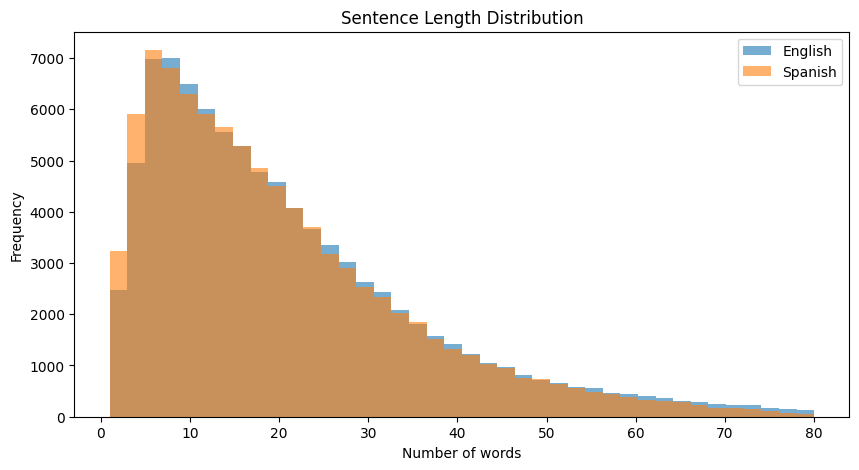

English 95th percentile: 53.0
Spanish 95th percentile: 50.0


In [ ]:

df["english_length"] = df["english"].apply(
    lambda x: len(x.split())
)

df["spanish_length"] = df["spanish"].apply(
    lambda x: len(x.split())
)

plt.figure(figsize=(10, 5))

plt.hist(
    df["english_length"],
    bins=40,
    alpha=0.6,
    label="English"
)

plt.hist(
    df["spanish_length"],
    bins=40,
    alpha=0.6,
    label="Spanish"
)

plt.xlabel("Number of words")
plt.ylabel("Frequency")
plt.title("Sentence Length Distribution")
plt.legend()
plt.show()

print("English 95th percentile:",
      df["english_length"].quantile(0.95))

print("Spanish 95th percentile:",
      df["spanish_length"].quantile(0.95))


In [ ]:
os.makedirs("tokenizers", exist_ok=True)

# Save training sentences
with open("tokenizers/english.txt", "w", encoding="utf-8") as f:
    for sentence in train_df["english"]:
        f.write(sentence + "\n")

with open("tokenizers/spanish.txt", "w", encoding="utf-8") as f:
    for sentence in train_df["spanish"]:
        f.write(sentence + "\n")


# Train English tokenizer
spm.SentencePieceTrainer.train(
    input="tokenizers/english.txt",
    model_prefix="tokenizers/english",
    vocab_size=8000,
    model_type="bpe",
    character_coverage=1.0,
    pad_id=0,
    unk_id=1,
    bos_id=2,
    eos_id=3
)

# Train Spanish tokenizer
spm.SentencePieceTrainer.train(
    input="tokenizers/spanish.txt",
    model_prefix="tokenizers/spanish",
    vocab_size=8000,
    model_type="bpe",
    character_coverage=1.0,
    pad_id=0,
    unk_id=1,
    bos_id=2,
    eos_id=3
)

english_tokenizer = spm.SentencePieceProcessor(
    model_file="tokenizers/english.model"
)

spanish_tokenizer = spm.SentencePieceProcessor(
    model_file="tokenizers/spanish.model"
)

print("English vocabulary:", english_tokenizer.get_piece_size())
print("Spanish vocabulary:", spanish_tokenizer.get_piece_size())


english_text = "I love machine learning."
spanish_text = "Me encanta el aprendizaje automático."

# Convert sentences into tokens
en_tokens = english_tokenizer.encode(
    english_text,
    out_type=str
)

es_tokens = spanish_tokenizer.encode(
    spanish_text,
    out_type=str
)

print("English tokens:", en_tokens)
print("Spanish tokens:", es_tokens)

# Convert tokens into numerical IDs
en_ids = english_tokenizer.encode(english_text)
es_ids = spanish_tokenizer.encode(spanish_text)

print("\nEnglish IDs:", en_ids)
print("Spanish IDs:", es_ids)



English vocabulary: 8000
Spanish vocabulary: 8000
English tokens: ['▁I', '▁love', '▁machine', '▁lear', 'ning', '.']
Spanish tokens: ['▁Me', '▁encanta', '▁el', '▁apren', 'di', 'za', 'je', '▁au', 't', 'om', 'ático', '.']

English IDs: [44, 691, 5495, 4679, 977, 7903]
Spanish IDs: [631, 3735, 38, 3889, 51, 173, 457, 1612, 7882, 49, 6848, 7889]


In [ ]:

class TranslationDataset(Dataset):

    def __init__(
        self,
        dataframe,
        english_tokenizer,
        spanish_tokenizer,
        max_length=80
    ):

        self.data = dataframe.reset_index(drop=True)

        self.en_tokenizer = english_tokenizer
        self.es_tokenizer = spanish_tokenizer

        self.max_length = max_length

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):

        english = self.data.iloc[index]["english"]
        spanish = self.data.iloc[index]["spanish"]

        # English token IDs
        en_ids = self.en_tokenizer.encode(english)

        # Spanish token IDs
        es_ids = self.es_tokenizer.encode(spanish)

        # Add BOS and EOS
        en_ids = [BOS_ID] + en_ids + [EOS_ID]
        es_ids = [BOS_ID] + es_ids + [EOS_ID]

        # Truncate if necessary, preserving EOS
        en_ids = en_ids[:self.max_length]
        es_ids = es_ids[:self.max_length]

        en_ids[-1] = EOS_ID
        es_ids[-1] = EOS_ID

        return {
            "english": torch.tensor(en_ids, dtype=torch.long),
            "spanish": torch.tensor(es_ids, dtype=torch.long)
        }

padding


In [ ]:

def collate_fn(batch):

    english_batch = [item["english"] for item in batch]
    spanish_batch = [item["spanish"] for item in batch]

    # Pad sequences within each batch
    english_batch = nn.utils.rnn.pad_sequence(
        english_batch,
        batch_first=True,
        padding_value=PAD_ID
    )

    spanish_batch = nn.utils.rnn.pad_sequence(
        spanish_batch,
        batch_first=True,
        padding_value=PAD_ID
    )

    return {
        "english": english_batch,
        "spanish": spanish_batch
    }


print("Padding function created successfully!")


Padding function created successfully!


In [ ]:

train_dataset = TranslationDataset(
    train_df,
    english_tokenizer,
    spanish_tokenizer,
    MAX_LENGTH
)

valid_dataset = TranslationDataset(
    valid_df,
    english_tokenizer,
    spanish_tokenizer,
    MAX_LENGTH
)

test_dataset = TranslationDataset(
    test_df,
    english_tokenizer,
    spanish_tokenizer,
    MAX_LENGTH
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(valid_dataset))
print("Testing samples:", len(test_dataset))


Training samples: 72113
Validation samples: 9014
Testing samples: 9015


In [ ]:

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

print("DataLoaders created successfully!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(valid_loader))
print("Testing batches:", len(test_loader))


DataLoaders created successfully!
Training batches: 1127
Validation batches: 141
Testing batches: 141


In [ ]:

# Special token IDs
PAD_ID = 0
UNK_ID = 1
BOS_ID = 2
EOS_ID = 3

# Model configuration
D_MODEL = 256
DROPOUT = 0.1

# Vocabulary sizes
SRC_VOCAB_SIZE = english_tokenizer.get_piece_size()
TGT_VOCAB_SIZE = spanish_tokenizer.get_piece_size()

print("Initialization successful!")
print("English vocabulary:", SRC_VOCAB_SIZE)
print("Spanish vocabulary:", TGT_VOCAB_SIZE)


Initialization successful!
English vocabulary: 8000
Spanish vocabulary: 8000


TOKEN EMBEDDING

In [ ]:

D_MODEL = 256

SRC_VOCAB_SIZE = english_tokenizer.get_piece_size()
TGT_VOCAB_SIZE = spanish_tokenizer.get_piece_size()

class TokenEmbedding(nn.Module):

    def __init__(self, vocab_size, d_model):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            d_model,
            padding_idx=PAD_ID
        )

        self.d_model = d_model

    def forward(self, x):

        return self.embedding(x) * math.sqrt(self.d_model)


# Separate embeddings for English and Spanish
src_embedding = TokenEmbedding(
    SRC_VOCAB_SIZE,
    D_MODEL
)

tgt_embedding = TokenEmbedding(
    TGT_VOCAB_SIZE,
    D_MODEL
)

print("Token Embedding created successfully!")


Token Embedding created successfully!


In [ ]:
position encodeing

In [ ]:

class PositionalEncoding(nn.Module):

    def __init__(self, d_model, max_len=5000, dropout=0.1):
        super().__init__()

        self.dropout = nn.Dropout(dropout)

        pe = torch.zeros(max_len, d_model)

        position = torch.arange(
            0, max_len
        ).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2) *
            (-math.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(
            position * div_term
        )

        pe[:, 1::2] = torch.cos(
            position * div_term
        )

        pe = pe.unsqueeze(0)

        self.register_buffer("pe", pe)

    def forward(self, x):

        x = x + self.pe[:, :x.size(1), :]

        return self.dropout(x)


positional_encoding = PositionalEncoding(
    D_MODEL,
    dropout=DROPOUT
)

print("Positional Encoding created successfully!")


Positional Encoding created successfully!


In [ ]:

class InputEmbedding(nn.Module):

    def __init__(self, vocab_size, d_model, dropout=0.1):

        super().__init__()

        self.token_embedding = TokenEmbedding(
            vocab_size,
            d_model
        )

        self.positional_encoding = PositionalEncoding(
            d_model,
            dropout=dropout
        )

    def forward(self, x):

        x = self.token_embedding(x)

        x = self.positional_encoding(x)

        return x


src_input_embedding = InputEmbedding(
    SRC_VOCAB_SIZE,
    D_MODEL,
    DROPOUT
)

tgt_input_embedding = InputEmbedding(
    TGT_VOCAB_SIZE,
    D_MODEL,
    DROPOUT
)

print("Input Embedding created successfully!")


Input Embedding created successfully!


In [ ]:

batch = next(iter(train_loader))

english = batch["english"].to(device)
spanish = batch["spanish"].to(device)

# Move embedding modules to GPU
src_input_embedding = src_input_embedding.to(device)
tgt_input_embedding = tgt_input_embedding.to(device)

# Generate embeddings
english_embedded = src_input_embedding(english)
spanish_embedded = tgt_input_embedding(spanish)

print("English input shape:", english.shape)
print("English embedding shape:", english_embedded.shape)

print("\nSpanish input shape:", spanish.shape)
print("Spanish embedding shape:", spanish_embedded.shape)


English input shape: torch.Size([64, 80])
English embedding shape: torch.Size([64, 80, 256])

Spanish input shape: torch.Size([64, 80])
Spanish embedding shape: torch.Size([64, 80, 256])


In [ ]:

class ScaledDotProductAttention(nn.Module):

    def __init__(self, dropout=0.1):
        super().__init__()

        self.dropout = nn.Dropout(dropout)

    def forward(self, Q, K, V, mask=None):

        # Dimension of Key vectors
        d_k = Q.size(-1)

        # Calculate attention scores
        scores = torch.matmul(
            Q,
            K.transpose(-2, -1)
        ) / math.sqrt(d_k)

        # Apply mask if provided
        if mask is not None:
            scores = scores.masked_fill(
                mask == 0,
                float("-inf")
            )

        # Convert scores into probabilities
        attention_weights = torch.softmax(
            scores,
            dim=-1
        )

        attention_weights = self.dropout(
            attention_weights
        )

        # Weighted sum of values
        output = torch.matmul(
            attention_weights,
            V
        )

        return output, attention_weights


print("Scaled Dot-Product Attention created!")


Scaled Dot-Product Attention created!


attention module

In [ ]:

# Create attention module
attention = ScaledDotProductAttention()

# Sample Q, K and V tensors
Q = torch.randn(2, 4, 8)
K = torch.randn(2, 4, 8)
V = torch.randn(2, 4, 8)

# Forward pass
output, weights = attention(Q, K, V)

print("Query shape:", Q.shape)
print("Key shape:", K.shape)
print("Value shape:", V.shape)

print("\nAttention output shape:", output.shape)
print("Attention weights shape:", weights.shape)

print("\nAttention weights:")
print(weights[0])


Query shape: torch.Size([2, 4, 8])
Key shape: torch.Size([2, 4, 8])
Value shape: torch.Size([2, 4, 8])

Attention output shape: torch.Size([2, 4, 8])
Attention weights shape: torch.Size([2, 4, 4])

Attention weights:
tensor([[0.0193, 0.2590, 0.6949, 0.1379],
        [0.0000, 0.1137, 0.0000, 0.4797],
        [0.0000, 0.3817, 0.2897, 0.3637],
        [0.6238, 0.1004, 0.3218, 0.0651]])


multi head attention

In [ ]:

NUM_HEADS = 8

class MultiHeadAttention(nn.Module):

    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()

        assert d_model % num_heads == 0

        self.d_model = d_model
        self.num_heads = num_heads
        self.head_dim = d_model // num_heads

        # Linear projections for Q, K and V
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)

        # Final output projection
        self.W_o = nn.Linear(d_model, d_model)

        self.attention = ScaledDotProductAttention(dropout)

    def split_heads(self, x):

        batch_size, seq_length, _ = x.shape

        x = x.view(
            batch_size,
            seq_length,
            self.num_heads,
            self.head_dim
        )

        return x.transpose(1, 2)

    def forward(self, query, key, value, mask=None):

        # Linear projections
        Q = self.W_q(query)
        K = self.W_k(key)
        V = self.W_v(value)

        # Split into multiple heads
        Q = self.split_heads(Q)
        K = self.split_heads(K)
        V = self.split_heads(V)

        # Attention calculation
        attention_output, attention_weights = self.attention(
            Q, K, V, mask
        )

        # Combine attention heads
        batch_size = query.size(0)

        attention_output = attention_output.transpose(1, 2)

        attention_output = attention_output.contiguous().view(
            batch_size,
            -1,
            self.d_model
        )

        # Final linear projection
        output = self.W_o(attention_output)

        return output, attention_weights


print("Multi-Head Attention implemented successfully!")


Multi-Head Attention implemented successfully!


In [ ]:

# Create Multi-Head Attention
mha = MultiHeadAttention(
    d_model=D_MODEL,
    num_heads=NUM_HEADS,
    dropout=DROPOUT
).to(device)

# Sample input
x = torch.randn(2, 10, D_MODEL).to(device)

# Forward pass
output, weights = mha(x, x, x)

print("Input shape:", x.shape)
print("Output shape:", output.shape)
print("Attention weights shape:", weights.shape)

print("\nHead dimension:", mha.head_dim)
print("Number of heads:", mha.num_heads)


Input shape: torch.Size([2, 10, 256])
Output shape: torch.Size([2, 10, 256])
Attention weights shape: torch.Size([2, 8, 10, 10])

Head dimension: 32
Number of heads: 8


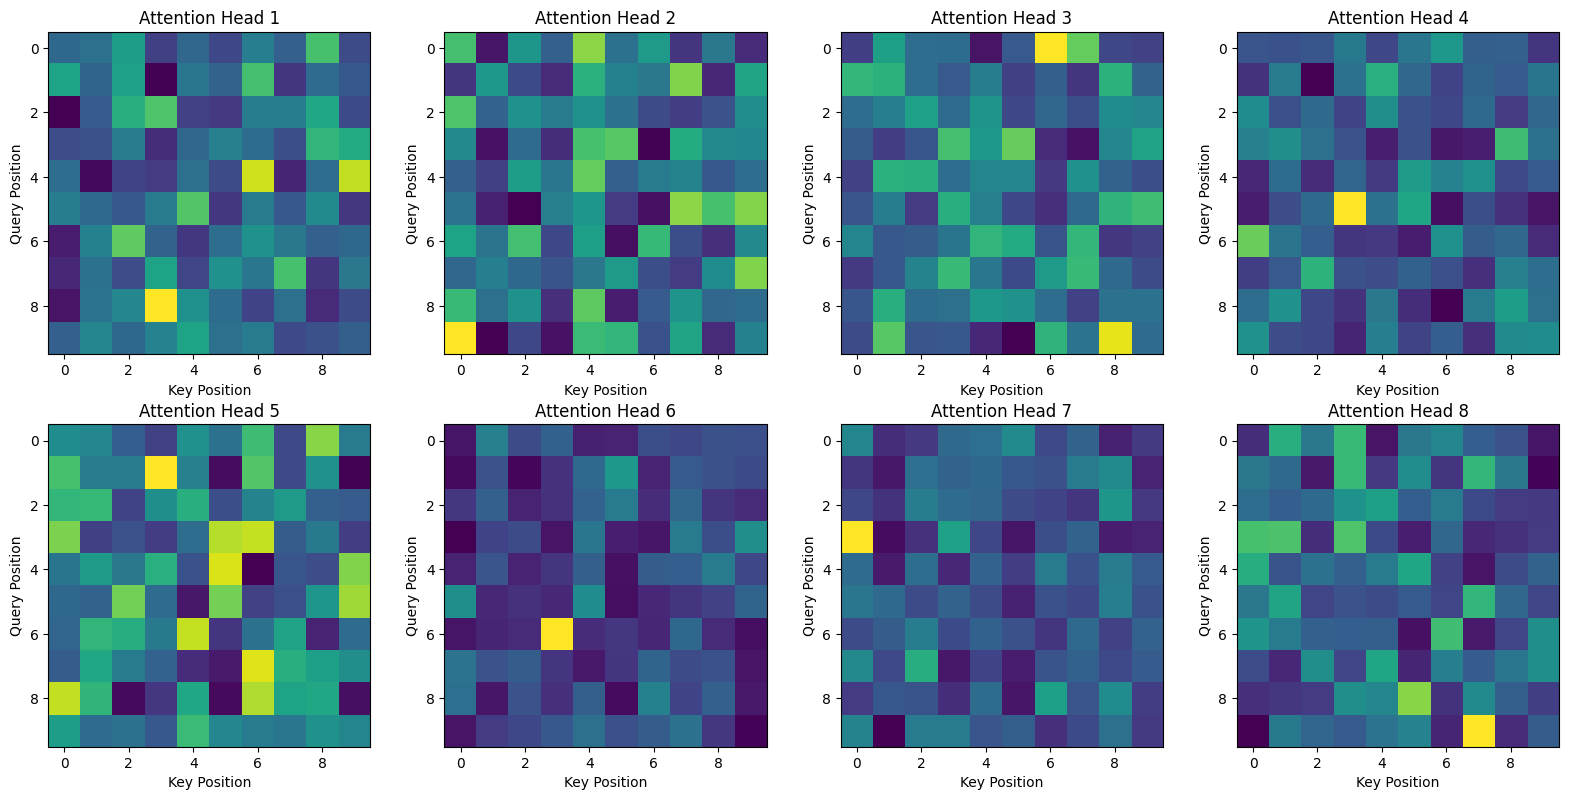

In [ ]:

# Switch off dropout for visualization
mha.eval()

with torch.no_grad():
    output, weights = mha(x, x, x)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i, ax in enumerate(axes.flat):

    ax.imshow(
        weights[0, i].cpu().numpy(),
        cmap="viridis"
    )

    ax.set_title(f"Attention Head {i+1}")
    ax.set_xlabel("Key Position")
    ax.set_ylabel("Query Position")

plt.tight_layout()
plt.show()


In [ ]:
D_FF = 1024

class PositionwiseFeedForward(nn.Module):

    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()

        self.linear1 = nn.Linear(d_model, d_ff)
        self.linear2 = nn.Linear(d_ff, d_model)

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):

        x = self.linear1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.linear2(x)

        return x

In [ ]:
class AddNorm(nn.Module):

    def __init__(self, d_model, dropout=0.1):
        super().__init__()

        self.norm = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, sublayer_output):

        output = x + self.dropout(sublayer_output)
        output = self.norm(output)

        return output

implement encoder

In [ ]:
class EncoderLayer(nn.Module):

    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()

        self.self_attention = MultiHeadAttention(
            d_model, num_heads, dropout
        )

        self.add_norm1 = AddNorm(d_model, dropout)

        self.feed_forward = PositionwiseFeedForward(
            d_model, d_ff, dropout
        )

        self.add_norm2 = AddNorm(d_model, dropout)

    def forward(self, x, src_mask):

        # Multi-Head Self-Attention
        attention_output, attention_weights = self.self_attention(
            x, x, x, src_mask
        )

        # Residual Connection + Layer Normalization
        x = self.add_norm1(x, attention_output)

        # Feed-Forward Network
        ffn_output = self.feed_forward(x)

        # Residual Connection + Layer Normalization
        x = self.add_norm2(x, ffn_output)

        return x, attention_weights

Decoder

In [ ]:
class DecoderLayer(nn.Module):

    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()

        # Masked self-attention
        self.self_attention = MultiHeadAttention(
            d_model, num_heads, dropout
        )
        self.add_norm1 = AddNorm(d_model, dropout)

        # Encoder-decoder cross-attention
        self.cross_attention = MultiHeadAttention(
            d_model, num_heads, dropout
        )
        self.add_norm2 = AddNorm(d_model, dropout)

        # Feed-forward network
        self.feed_forward = PositionwiseFeedForward(
            d_model, d_ff, dropout
        )
        self.add_norm3 = AddNorm(d_model, dropout)

    def forward(self, x, encoder_output, tgt_mask, src_mask):

        # 1. Masked self-attention
        attention_output, self_attention_weights = self.self_attention(
            x, x, x, tgt_mask
        )

        x = self.add_norm1(x, attention_output)

        # 2. Encoder-decoder cross-attention
        cross_output, cross_attention_weights = self.cross_attention(
            x, encoder_output, encoder_output, src_mask
        )

        x = self.add_norm2(x, cross_output)

        # 3. Feed-forward network
        ffn_output = self.feed_forward(x)

        x = self.add_norm3(x, ffn_output)

        return x, self_attention_weights, cross_attention_weights

In [ ]:
NUM_ENCODER_LAYERS = 4
NUM_DECODER_LAYERS = 4
class Transformer(nn.Module):

    def __init__(
        self,
        src_vocab_size,
        tgt_vocab_size,
        d_model=256,
        num_heads=8,
        num_encoder_layers=4,
        num_decoder_layers=4,
        d_ff=1024,
        dropout=0.1,
        max_len=5000
    ):
        super().__init__()

        # English and Spanish embeddings
        self.src_embedding = InputEmbedding(
        src_vocab_size, d_model, dropout)

        self.tgt_embedding = InputEmbedding(
    tgt_vocab_size, d_model, dropout)

        # Encoder layers
        self.encoder_layers = nn.ModuleList([
            EncoderLayer(d_model, num_heads, d_ff, dropout)
            for _ in range(num_encoder_layers)
        ])

        # Decoder layers
        self.decoder_layers = nn.ModuleList([
            DecoderLayer(d_model, num_heads, d_ff, dropout)
            for _ in range(num_decoder_layers)
        ])

        # Final vocabulary prediction
        self.generator = nn.Linear(d_model, tgt_vocab_size)

        self.d_model = d_model

    def encode(self, src, src_mask):

        x = self.src_embedding(src)

        for layer in self.encoder_layers:
            x, _ = layer(x, src_mask)

        return x

    def decode(self, tgt, encoder_output, tgt_mask, src_mask):

        x = self.tgt_embedding(tgt)

        for layer in self.decoder_layers:
            x, _, _ = layer(
                x, encoder_output, tgt_mask, src_mask
            )

        return self.generator(x)

    def forward(self, src, tgt, src_mask, tgt_mask):

        encoder_output = self.encode(src, src_mask)

        output = self.decode(
            tgt,
            encoder_output,
            tgt_mask,
            src_mask
        )

        return output

model = Transformer(
    src_vocab_size=SRC_VOCAB_SIZE,
    tgt_vocab_size=TGT_VOCAB_SIZE,
    d_model=D_MODEL,
    num_heads=NUM_HEADS,
    num_encoder_layers=NUM_ENCODER_LAYERS,
    num_decoder_layers=NUM_DECODER_LAYERS,
    d_ff=D_FF,
    dropout=DROPOUT,
    max_len=MAX_LENGTH
).to(device)

total_parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Model created successfully!")
print(f"Total trainable parameters: {total_parameters:,}")
print("Device:", device)


Model created successfully!
Total trainable parameters: 13,524,800
Device: cuda


In [ ]:
def create_masks(src, tgt):

    # Source padding mask
    src_mask = (src != PAD_ID).unsqueeze(1).unsqueeze(2)

    # Target padding mask
    tgt_pad_mask = (tgt != PAD_ID).unsqueeze(1).unsqueeze(2)

    # Causal mask: prevents looking at future tokens
    tgt_length = tgt.size(1)

    causal_mask = torch.tril(
        torch.ones(
            tgt_length,
            tgt_length,
            device=tgt.device
        )
    ).bool().unsqueeze(0).unsqueeze(0)

    # Combine target padding and causal masks
    tgt_mask = tgt_pad_mask & causal_mask

    return src_mask, tgt_mask


In [ ]:
LEARNING_RATE = 0.0003
EPOCHS = 20

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    betas=(0.9, 0.98),
    eps=1e-9
)

criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)

def train_one_epoch(model, train_loader, optimizer, criterion):

    model.train()

    total_loss = 0

    progress_bar = tqdm(train_loader, desc="Training")

    for batch in progress_bar:

        src = batch["english"].to(device)
        tgt = batch["spanish"].to(device)

        # Shift target sequence
        tgt_input = tgt[:, :-1]
        tgt_output = tgt[:, 1:]

        # Create masks
        src_mask, tgt_mask = create_masks(src, tgt_input)

        # Clear previous gradients
        optimizer.zero_grad(set_to_none=True)

        # Forward pass
        predictions = model(
            src,
            tgt_input,
            src_mask,
            tgt_mask
        )

        # Calculate loss
        loss = criterion(
            predictions.reshape(-1, TGT_VOCAB_SIZE),
            tgt_output.reshape(-1)
        )

        # Backpropagation
        loss.backward()

        # Prevent excessively large gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        # Update model parameters
        optimizer.step()

        total_loss += loss.item()

        progress_bar.set_postfix(loss=f"{loss.item():.4f}")

    return total_loss / len(train_loader)

In [ ]:
def train_one_epoch(model, train_loader, optimizer, criterion):

    model.train()

    total_loss = 0

    progress_bar = tqdm(train_loader, desc="Training")

    for batch in progress_bar:

        src = batch["english"].to(device)
        tgt = batch["spanish"].to(device)

        # Shift target sequence
        tgt_input = tgt[:, :-1]
        tgt_output = tgt[:, 1:]

        # Create masks
        src_mask, tgt_mask = create_masks(src, tgt_input)

        # Clear previous gradients
        optimizer.zero_grad(set_to_none=True)

        # Forward pass
        predictions = model(
            src,
            tgt_input,
            src_mask,
            tgt_mask
        )

        # Calculate loss
        loss = criterion(
            predictions.reshape(-1, TGT_VOCAB_SIZE),
            tgt_output.reshape(-1)
        )

        # Backpropagation
        loss.backward()

        # Prevent excessively large gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        # Update model parameters
        optimizer.step()

        total_loss += loss.item()

        progress_bar.set_postfix(loss=f"{loss.item():.4f}")

    return total_loss / len(train_loader)

def validate(model, valid_loader, criterion):

    model.eval()

    total_loss = 0

    with torch.no_grad():

        for batch in tqdm(valid_loader, desc="Validation"):

            src = batch["english"].to(device)
            tgt = batch["spanish"].to(device)

            tgt_input = tgt[:, :-1]
            tgt_output = tgt[:, 1:]

            src_mask, tgt_mask = create_masks(src, tgt_input)

            predictions = model(
                src,
                tgt_input,
                src_mask,
                tgt_mask
            )

            loss = criterion(
                predictions.reshape(-1, TGT_VOCAB_SIZE),
                tgt_output.reshape(-1)
            )

            total_loss += loss.item()

    return total_loss / len(valid_loader)

In [ ]:
def create_masks(src, tgt):

    # Source padding mask
    src_mask = (src != PAD_ID).unsqueeze(1).unsqueeze(2)

    # Target padding mask
    tgt_pad_mask = (tgt != PAD_ID).unsqueeze(1).unsqueeze(2)

    # Causal mask
    tgt_length = tgt.size(1)

    causal_mask = torch.tril(
        torch.ones(
            tgt_length,
            tgt_length,
            device=tgt.device
        )
    ).bool().unsqueeze(0).unsqueeze(0)

    # Combined target mask
    tgt_mask = tgt_pad_mask & causal_mask

    return src_mask, tgt_mask

In [ ]:
train_losses = []
valid_losses = []

for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch + 1}/{EPOCHS}")

    train_loss = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion
    )

    valid_loss = validate(
        model,
        valid_loader,
        criterion
    )

    train_losses.append(train_loss)
    valid_losses.append(valid_loss)

    print(f"Training Loss:   {train_loss:.4f}")
    print(f"Validation Loss: {valid_loss:.4f}")

    # Save the best model
    if epoch == 0 or valid_loss < min(valid_losses[:-1]):
        torch.save(model.state_dict(), "best_transformer.pth")
        print("Best model saved!")


Epoch 1/20


Training:   0%|          | 0/1127 [00:00<?, ?it/s]

Validation:   0%|          | 0/141 [00:00<?, ?it/s]

Training Loss:   5.7224
Validation Loss: 5.0577
Best model saved!

Epoch 2/20


Training:   0%|          | 0/1127 [00:00<?, ?it/s]

Validation:   0%|          | 0/141 [00:00<?, ?it/s]

... (51 outputs left out)

Training Loss:   3.1405
Validation Loss: 3.6027
Best model saved!

Epoch 20/20


Training:   0%|          | 0/1127 [00:00<?, ?it/s]

Validation:   0%|          | 0/141 [00:00<?, ?it/s]

Training Loss:   3.1095
Validation Loss: 3.6023
Best model saved!


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os
import shutil
import json
import torch

SAVE_DIR = "/content/drive/MyDrive/Transformer_Translation"
os.makedirs(SAVE_DIR, exist_ok=True)

# Save trained model
torch.save(
    model.state_dict(),
    f"{SAVE_DIR}/best_transformer.pth"
)

# Save tokenizers
shutil.copy("tokenizers/english.model", SAVE_DIR)
shutil.copy("tokenizers/spanish.model", SAVE_DIR)

# Save training history
with open(f"{SAVE_DIR}/loss_history.json", "w") as f:
    json.dump({
        "train_losses": train_losses,
        "valid_losses": valid_losses
    }, f)

print("Model, tokenizers and loss history saved successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model, tokenizers and loss history saved successfully!


In [ ]:
model.load_state_dict(
    torch.load(
        f"{SAVE_DIR}/best_transformer.pth",
        map_location=device
    )
)

model.eval()

print("Best Transformer model loaded successfully!")

Best Transformer model loaded successfully!


In [ ]:
def translate_sentence(sentence, max_len=80):
    model.eval()

    # Encode english sentence
    en_ids = [BOS_ID] + english_tokenizer.encode(sentence) + [EOS_ID]
    src_tensor = torch.tensor(en_ids, dtype=torch.long, device=device).unsqueeze(0) # (1, src_len)

    # Create source mask
    src_mask = (src_tensor != PAD_ID).unsqueeze(1).unsqueeze(2) # (1, 1, 1, src_len)

    # Encode the source sequence
    with torch.no_grad():
        encoder_output = model.encode(src_tensor, src_mask)

    # Start decoder with BOS token
    tgt_ids = [BOS_ID]

    for _ in range(max_len):
        tgt_tensor = torch.tensor(tgt_ids, dtype=torch.long, device=device).unsqueeze(0) # (1, tgt_len)

        # Create target mask (padding + causal)
        tgt_pad_mask = (tgt_tensor != PAD_ID).unsqueeze(1).unsqueeze(2)
        tgt_len = tgt_tensor.size(1)
        causal_mask = torch.tril(torch.ones(tgt_len, tgt_len, device=device)).bool().unsqueeze(0).unsqueeze(0)
        tgt_mask = tgt_pad_mask & causal_mask

        # Decode step
        with torch.no_grad():
            predictions = model.decode(tgt_tensor, encoder_output, tgt_mask, src_mask)

        # Get the token with the highest score at the last position
        next_token = predictions[0, -1, :].argmax().item()
        tgt_ids.append(next_token)

        # If we predict EOS, stop decoding
        if next_token == EOS_ID:
            break

    # Convert predicted IDs back to string
    translated_sentence = spanish_tokenizer.decode(tgt_ids)
    return translated_sentence

In [ ]:
test_sentences = [
    "Hello, how are you?",
    "I love learning new things.",
    "What is your name?",
    "I am a student.",
    "Good morning.",
    "I want to learn artificial intelligence."
]

for sentence in test_sentences:
    translation = translate_sentence(sentence)

    print("English:", sentence)
    print("Spanish:", translation)
    print("-" * 50)

English: Hello, how are you?
Spanish: ¿Cómo estás?
--------------------------------------------------
English: I love learning new things.
Spanish: Yo he querido ocuparme de amor.
--------------------------------------------------
English: What is your name?
Spanish: ¿Qué es vuestro nombre?
--------------------------------------------------
English: I am a student.
Spanish: Soy yo.
--------------------------------------------------
English: Good morning.
Spanish: Buenas noches.
--------------------------------------------------
English: I want to learn artificial intelligence.
Spanish: Yo quería estudiar la inteligencia de la inteligencia.
--------------------------------------------------


In [ ]:
!pip install -q sacrebleu
def translate_batch(src):
    model.eval()

    src_mask = (src != PAD_ID).unsqueeze(1).unsqueeze(2)

    with torch.no_grad():
        encoder_output = model.encode(src, src_mask)

        batch_size = src.size(0)

        tgt = torch.full(
            (batch_size, 1),
            BOS_ID,
            dtype=torch.long,
            device=device
        )

        finished = torch.zeros(
            batch_size, dtype=torch.bool, device=device
        )

        for _ in range(MAX_LENGTH - 1):

            tgt_len = tgt.size(1)

            causal_mask = torch.tril(
                torch.ones(tgt_len, tgt_len, device=device)
            ).bool().unsqueeze(0).unsqueeze(0)

            tgt_pad_mask = (tgt != PAD_ID).unsqueeze(1).unsqueeze(2)
            tgt_mask = tgt_pad_mask & causal_mask

            output = model.decode(
                tgt, encoder_output, tgt_mask, src_mask
            )

            next_tokens = output[:, -1, :].argmax(dim=-1)

            next_tokens = torch.where(
                finished,
                torch.full_like(next_tokens, PAD_ID),
                next_tokens
            )

            tgt = torch.cat(
                [tgt, next_tokens.unsqueeze(1)], dim=1
            )

            finished |= (next_tokens == EOS_ID)

            if finished.all():
                break

    return tgt

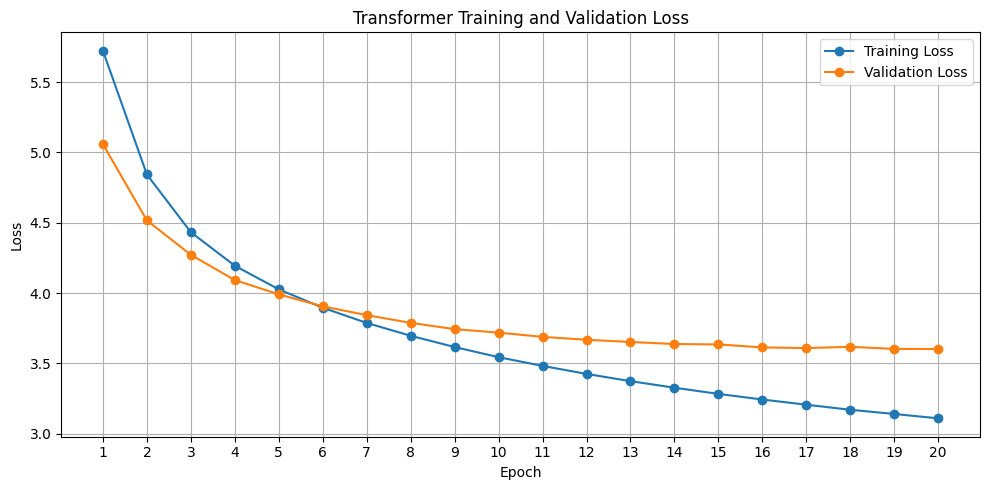

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(10, 5))

plt.plot(epochs, train_losses,
         marker="o", label="Training Loss")

plt.plot(epochs, valid_losses,
         marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Transformer Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.xticks(epochs)
plt.tight_layout()
plt.show()

In [ ]:
from sacrebleu import corpus_bleu
from tqdm.auto import tqdm

predictions = []
references = []

model.eval()

for batch in tqdm(test_loader, desc="BLEU Evaluation"):

    src = batch["english"].to(device)
    tgt = batch["spanish"]

    generated = translate_batch(src).cpu().tolist()

    for pred_ids, ref_ids in zip(generated, tgt.tolist()):

        # Decode predicted translation
        pred_tokens = []

        for token in pred_ids:
            if token == EOS_ID:
                break
            if token not in (PAD_ID, BOS_ID):
                pred_tokens.append(int(token))

        predictions.append(
            spanish_tokenizer.decode(pred_tokens)
        )

        # Decode actual reference translation
        ref_tokens = []

        for token in ref_ids:
            if token == EOS_ID:
                break
            if token not in (PAD_ID, BOS_ID):
                ref_tokens.append(int(token))

        references.append(
            spanish_tokenizer.decode(ref_tokens)
        )

# Calculate BLEU
bleu = corpus_bleu(predictions, [references])

print("Test BLEU Score:", round(bleu.score, 2))
print(bleu)

BLEU Evaluation:   0%|          | 0/141 [00:00<?, ?it/s]

Test BLEU Score: 5.1
BLEU = 5.10 32.1/8.5/2.7/0.9 (BP = 1.000 ratio = 1.134 hyp_len = 228279 ref_len = 201338)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

SAVE_DIR = "/content/drive/MyDrive/Transformer_Translation"

english_tokenizer = spm.SentencePieceProcessor(
    model_file=f"{SAVE_DIR}/english.model"
)

spanish_tokenizer = spm.SentencePieceProcessor(
    model_file=f"{SAVE_DIR}/spanish.model"
)

print("English vocabulary:", english_tokenizer.get_piece_size())
print("Spanish vocabulary:", spanish_tokenizer.get_piece_size())

print("Tokenizers loaded successfully!")